## TP 1 : Exploration Dataset

- Explorer HuggingFace
- Charger un Dataset
- Description du contenu du dataset
- Description statistique du dataset
- Analyse tokens vs lemmes
- Distribution des tokens
- Loi de Zipf

### Énoncé

Charger un jeu de données

Définir la classification (ce qu'on cherche à prédire)

Convertir un document (texte brut) sous une forme exploitable par un modèle d'apprentissage automatique

In [35]:
from tqdm.auto import tqdm

### Charger un jeu de données

In [36]:
from datasets import load_dataset_builder

dataset_path = "AntoineBourgois/Gallica_Hors-d-Usage_cleaned"

In [37]:
builder = load_dataset_builder(dataset_path)

print(builder.info.features)

{'doc_id': Value('string'), 'date_publication': Value('int64'), 'titre': Value('string'), 'auteur': Value('string'), 'auteur_genre': Value('string'), 'auteur_nom': Value('string'), 'auteur_prenom': Value('string'), 'genre_litteraire': Value('string'), 'texte': Value('large_string'), 'tokens': Value('string'), 'lemmes': Value('string')}


### HuggingFace, un acteur central en Traitement Automatique du Langage (TAL)

Visitez [Hugging Face](https://huggingface.co/) et prenez 5 minutes pour explorer les principaux onglets [`Models`](https://huggingface.co/models) et [`Datasets`](https://huggingface.co/datasets)

In [38]:
builder = load_dataset_builder(dataset_path,)

print(f"Le jeu de données {dataset_path!r} contient {len(builder.info.splits)} sous-ensembles :")
for name, split in builder.info.splits.items():
    print(f"    {name:<20}{split.num_examples:<6,} documents")

Le jeu de données 'AntoineBourgois/Gallica_Hors-d-Usage_cleaned' contient 5 sous-ensembles :
    tous                6,156  documents
    auteur_genre        200    documents
    auteur              200    documents
    date_publication    200    documents
    genre_litteraire    200    documents


Nous commençons par sélectionner l'un des 4 sous-ensembles de 200 documents.

La variable `label_column` correspond, pour chaque sous-ensemble, à ce qu'on souhaite prédire avec le modèle de classification.

In [39]:
# sous_ensemble, label_column = "auteur_genre", "auteur_genre"
# sous_ensemble, label_column = "auteur", "auteur"
# sous_ensemble, label_column = "date_publication", "date_publication"
sous_ensemble, label_column = "genre_litteraire", "genre_litteraire"

In [40]:
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

dataset_path = "AntoineBourgois/Gallica_Hors-d-Usage_cleaned"
sous_ensemble = "genre_litteraire"

fichier_local = hf_hub_download(
    repo_id=dataset_path,
    filename=f"data/{sous_ensemble}-00000-of-00001.parquet",
    repo_type="dataset",
    force_download=True,
)

table = pq.read_table(fichier_local)
dataset = table.to_pylist()

print("Nombre de documents :", len(dataset))

def conversions_string_vers_liste(string):
    if isinstance(string, str):
        return string.split(" ")

for document in dataset:
    document["tokens"] = conversions_string_vers_liste(document["tokens"])
    document["lemmes"] = conversions_string_vers_liste(document["lemmes"])

data/genre_litteraire-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  290MB            

data/genre_litteraire-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Nombre de documents : 200


### Structure du dataset

In [41]:
print(f"Type dataset: {type(dataset)}")
print(f"Longueur dataset: {len(dataset)}")

doc_0 = dataset[0]
print(f"Type 1er document: {type(doc_0)}")
print(f"Clés d'un document: {doc_0.keys()}")

Type dataset: <class 'list'>
Longueur dataset: 200
Type 1er document: <class 'dict'>
Clés d'un document: dict_keys(['doc_id', 'date_publication', 'titre', 'auteur', 'auteur_genre', 'auteur_nom', 'auteur_prenom', 'genre_litteraire', 'texte', 'tokens', 'lemmes'])


In [42]:
for key, value in doc_0.items():
    print(f"{key:<20} {type(value)}    {str(value)[:100]}")

doc_id               <class 'str'>    HDU-00941
date_publication     <class 'int'>    1832
titre                <class 'str'>    Les pilotes de l'Iroise
auteur               <class 'str'>    Édouard Corbière
auteur_genre         <class 'str'>    masculin
auteur_nom           <class 'str'>    Corbière
auteur_prenom        <class 'str'>    Édouard
genre_litteraire     <class 'str'>    aventure
texte                <class 'str'>    Tanguy et de ses deux compagnons. La conversation qu'ils avaient entamée en bas1 Les navires qui ent
tokens               <class 'list'>    ['Tanguy', 'et', 'de', 'ses', 'deux', 'compagnons', '.', 'La', 'conversation', "qu'", 'ils', 'avaien
lemmes               <class 'list'>    ['tanguy', 'et', 'de', 'son', 'deux', 'compagnon', '.', 'le', 'conversation', 'que', 'il', 'avoir', 


Nous remarquons que, pour des raisons de mémoire, les champs `tokens` et `lemmes` sont stockés sous forme la forme d'une longue chaîne de charactères (type `string`)

Commençons par les convertir en listes.

In [43]:
print(doc_0["texte"][:50])
print(doc_0["tokens"][:20])
print(doc_0["lemmes"][:20])

Tanguy et de ses deux compagnons. La conversation 
['Tanguy', 'et', 'de', 'ses', 'deux', 'compagnons', '.', 'La', 'conversation', "qu'", 'ils', 'avaient', 'entamée', 'en', 'bas1', 'Les', 'navires', 'qui', 'entrent', 'à']
['tanguy', 'et', 'de', 'son', 'deux', 'compagnon', '.', 'le', 'conversation', 'que', 'il', 'avoir', 'entamer', 'en', 'bas1', 'le', 'navire', 'qui', 'entrer', 'à']


In [44]:
all_publication_date = [doc["date_publication"] for doc in dataset]
print("Min Year\t:", min(all_publication_date))
print("Max Year\t:", max(all_publication_date))
print("Mean Year\t:", int(sum(all_publication_date)/len(all_publication_date)))

Min Year	: 1832
Max Year	: 1946
Mean Year	: 1883


In [45]:
from collections import Counter
all_authors = [doc["auteur"] for doc in dataset]
Counter(all_authors).most_common(10)

[('Xavier de Montépin', 13),
 ('Paul Féval', 7),
 ('Jules Verne', 7),
 ('Jules Lermina', 5),
 ('Jules Mary', 5),
 ('Gabriel de La Landelle', 4),
 ('Paul Saunière', 3),
 ('Raoul de Navery', 3),
 ('Émile Richebourg', 3),
 ('Alexis Bouvier', 3)]

In [46]:
all_authors_gender = [doc["auteur_genre"] for doc in dataset]
Counter(all_authors_gender).most_common()

[('masculin', 189), ('féminin', 11)]

In [47]:
all_genre = [doc["genre_litteraire"] for doc in dataset]
Counter(all_genre).most_common()

[('aventure', 100), ('detective', 100)]

### Vocabulaire

Construire un dictionnaire du vocabulaire du corpus.

In [48]:
all_tokens = [token
              for document in dataset
              for token in document["tokens"]
              ]

In [49]:
vocab = sorted(set(all_tokens))
print(f"Taille du corpus: {len(all_tokens):,} tokens")
print(f"Taille du vocabulaire: {len(vocab):,} tokens")

Taille du corpus: 32,819,079 tokens
Taille du vocabulaire: 391,868 tokens


In [50]:
import pandas as pd
from collections import Counter

vocab_counter = Counter(all_tokens).most_common(15)

df = pd.DataFrame([
    {
        "Rang": i + 1,
        "Token": word,
        "Fréquence (%)": 100 * count / len(all_tokens)
    }
    for i, (word, count) in enumerate(vocab_counter)
])

print(df.to_string(
    index=False,
    formatters={"Fréquence (%)": "{:.2f}%".format},
    justify="center"
))

 Rang Token Fréquence (%)
   1     ,      6.58%    
   2     .      3.92%    
   3    de      3.31%    
   4    la      1.90%    
   5    le      1.70%    
   6    et      1.65%    
   7     à      1.61%    
   8    l'      1.12%    
   9    un      1.07%    
  10   que      1.06%    
  11    il      1.01%    
  12   les      0.97%    
  13    en      0.87%    
  14    d'      0.85%    
  15   une      0.76%    


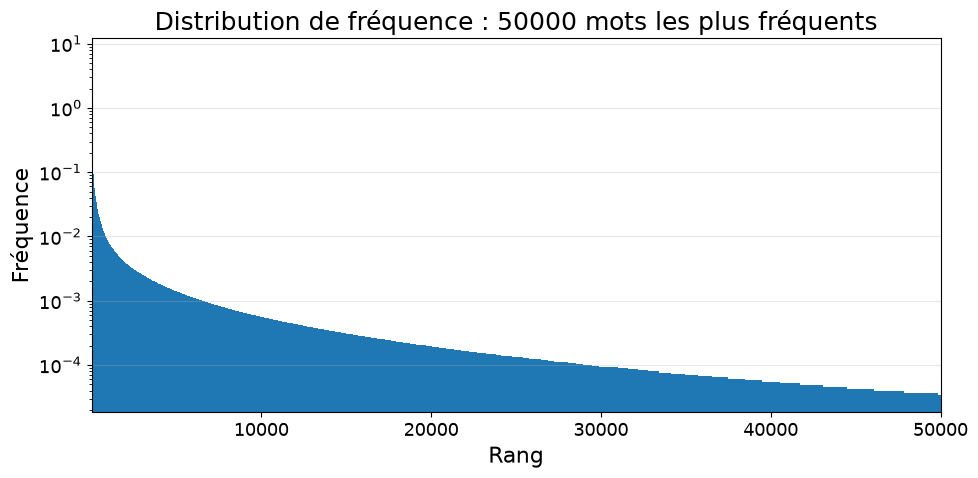

In [51]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# Global font settings
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
})

vocab_counter = Counter(all_tokens)

frequencies = sorted(vocab_counter.values(), reverse=True)

N = 50000
frequencies = [n * 100 / len(all_tokens) for n in frequencies[:N]]
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(10, 5))
plt.bar(ranks, frequencies, width=1.0)

plt.xlabel("Rang")
plt.ylabel("Fréquence")
plt.title(f"Distribution de fréquence : {N} mots les plus fréquents")

plt.xlim(1, N)
plt.grid(axis="y", alpha=0.3)
plt.yscale("log")
plt.tight_layout()
plt.show()

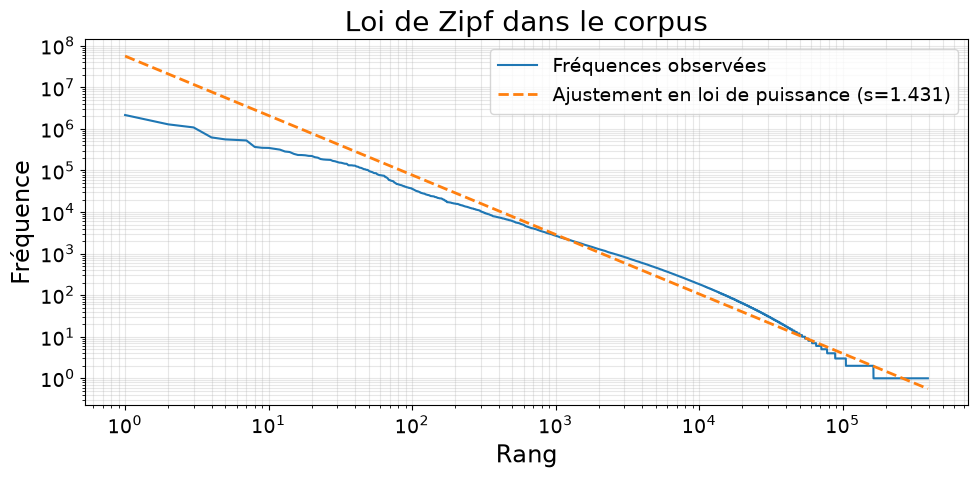

Exposant de Zipf estimé : 1.4309


In [52]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# Global font settings
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 20,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})

vocab_counter = Counter(all_tokens)
frequencies = np.array(sorted(vocab_counter.values(), reverse=True))
ranks = np.arange(1, len(frequencies) + 1)

# Log-transform
log_ranks = np.log(ranks)
log_freqs = np.log(frequencies)

# Fit a linear regression in log-log space
slope, intercept = np.polyfit(log_ranks, log_freqs, 1)

# Predicted values
fitted_freqs = np.exp(intercept) * ranks ** slope

# Plot
plt.figure(figsize=(10, 5))

plt.loglog(ranks, frequencies, label="Fréquences observées")
plt.loglog(
    ranks,
    fitted_freqs,
    "--",
    linewidth=2,
    label=f"Ajustement en loi de puissance (s={-slope:.3f})"
)

plt.xlabel("Rang")
plt.ylabel("Fréquence")
plt.title("Loi de Zipf dans le corpus")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Exposant de Zipf estimé : {-slope:.4f}")

In [53]:
sentences_tokens = [
    [token.lower() for token in doc["tokens"]]
    for doc in dataset
]

# Build vocabulary from all documents
word_counts = Counter(
    token
    for doc in sentences_tokens
    for token in doc
)

vocab = sorted(word_counts.keys())

total_tokens = sum(len(doc) for doc in sentences_tokens)

print("Documents:", len(sentences_tokens))
print("Total tokens:", total_tokens)
print("Vocabulary:", len(vocab))
print("Average document length:", total_tokens / len(sentences_tokens))

Documents: 200
Total tokens: 32819611
Vocabulary: 323088
Average document length: 164098.055


In [54]:
from collections import Counter

word_counts = Counter(
    token
    for doc in sentences_tokens
    for token in doc
)

print("Vocabulary:", len(word_counts))
print("Words occurring once:", sum(c == 1 for c in word_counts.values()))
print("Words occurring fewer than 5 times:", sum(c < 5 for c in word_counts.values()))
print("Words occurring fewer than 20 times:", sum(c < 20 for c in word_counts.values()))

Vocabulary: 323088
Words occurring once: 202867
Words occurring fewer than 5 times: 272571
Words occurring fewer than 20 times: 298144


In [55]:
min_count = 50

vocab = [
    word for word, count in word_counts.items()
    if count >= min_count
]

word_to_id = {word: i for i, word in enumerate(vocab)}
print(len(word_to_id))

15757


In [56]:
from collections import Counter
from scipy.sparse import coo_matrix
from sklearn.preprocessing import normalize

N = 2

# Map each word to an integer index
word_to_id = {word: i for i, word in enumerate(vocab)}

# Count co-occurrences
pair_counts = Counter()

for tokens in tqdm(sentences_tokens):
    ids = [word_to_id[w] for w in tokens if w in word_to_id]

    for i, target in enumerate(ids):

        start = max(0, i - N)
        end = min(len(ids), i + N + 1)

        for j in range(start, end):
            if i != j:
                context = ids[j]
                pair_counts[(target, context)] += 1

  0%|          | 0/200 [00:00<?, ?it/s]

In [57]:
# Build a sparse matrix
rows = [pair[0] for pair in pair_counts]
cols = [pair[1] for pair in pair_counts]
data = list(pair_counts.values())

cooc_matrix = coo_matrix(
    (data, (rows, cols)),
    shape=(len(vocab), len(vocab))
).tocsr()

# L1 normalization: each non-zero row sums to 1
cooc_matrix_normalized = normalize(
    cooc_matrix,
    norm="l1",
    axis=1
)

In [58]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def most_similar(word, matrix, word_to_id, vocab, top_n=10):

    if word not in word_to_id:
        print(f"'{word}' is not in the vocabulary.")
        return

    word_id = word_to_id[word]

    # Similarity between target vector and all other vectors
    similarities = cosine_similarity(
        matrix[word_id],
        matrix
    ).flatten()

    # Sort by decreasing similarity
    closest_ids = np.argsort(similarities)[::-1]

    results = []
    for idx in closest_ids:
        if idx != word_id:
            results.append((vocab[idx], similarities[idx]))

        if len(results) == top_n:
            break

    return results

In [59]:
most_similar(
    "homme",
    cooc_matrix_normalized,
    word_to_id,
    vocab,
    top_n=10
)

[('femme', np.float64(0.9619812677104206)),
 ('gentilhomme', np.float64(0.9533192061257556)),
 ('aventurier', np.float64(0.9506581539752782)),
 ('diplomate', np.float64(0.9461689980074923)),
 ('individu', np.float64(0.9457040174049635)),
 ('animal', np.float64(0.9440882361527555)),
 ('personnage', np.float64(0.9435397936364484)),
 ('gens', np.float64(0.9423283855381632)),
 ('couple', np.float64(0.9422218596291606)),
 ('document', np.float64(0.9401605265957094))]

In [60]:
for word in ["chien", "chat", "maison", "voiture"]:
    print(word, word_counts[word])

chien 3511
chat 676
maison 17708
voiture 7748


In [61]:
import numpy as np
from scipy.sparse import coo_matrix

def compute_ppmi(cooc_matrix):
    cooc = cooc_matrix.tocoo()

    total = cooc.data.sum()
    row_sums = np.asarray(cooc_matrix.sum(axis=1)).ravel()
    col_sums = np.asarray(cooc_matrix.sum(axis=0)).ravel()

    pmi = np.log(
        (cooc.data * total) /
        (row_sums[cooc.row] * col_sums[cooc.col])
    )

    ppmi = np.maximum(pmi, 0)

    return coo_matrix(
        (ppmi, (cooc.row, cooc.col)),
        shape=cooc_matrix.shape
    ).tocsr()

ppmi_matrix = compute_ppmi(cooc_matrix)

In [62]:
most_similar(
    "femme",
    ppmi_matrix,
    word_to_id,
    vocab,
    top_n=10
)

[('fille', np.float64(0.3062212562119892)),
 ('homme', np.float64(0.24516150900717862)),
 ('lui', np.float64(0.23701788354841238)),
 (',', np.float64(0.2275501238536207)),
 ('jeune', np.float64(0.21435124033759248)),
 ('et', np.float64(0.2127122566358985)),
 ('enfant', np.float64(0.2088057891043474)),
 ('mère', np.float64(0.19930506781876364)),
 ('créature', np.float64(0.19526009247706508)),
 ('.', np.float64(0.1951657334674429))]

In [63]:
from sklearn.decomposition import TruncatedSVD

def compute_ppmi(cooc_matrix, alpha=0.75, shift=0.0):
    cooc = cooc_matrix.tocoo()

    total = cooc.data.sum()
    row_sums = np.asarray(cooc_matrix.sum(axis=1)).ravel()
    col_sums = np.asarray(cooc_matrix.sum(axis=0)).ravel() ** alpha

    p_wc = cooc.data / total
    p_w = row_sums[cooc.row] / total
    p_c = col_sums[cooc.col] / col_sums.sum()

    pmi = np.log(p_wc / (p_w * p_c))
    ppmi = np.maximum(pmi - shift, 0)   # shift = np.log(k) gives shifted PPMI

    result = coo_matrix((ppmi, (cooc.row, cooc.col)), shape=cooc_matrix.shape).tocsr()
    result.eliminate_zeros()
    return result

ppmi_matrix = compute_ppmi(cooc_matrix, alpha=0.75)

svd = TruncatedSVD(n_components=300, random_state=0)
us = svd.fit_transform(ppmi_matrix)              # U * S
embeddings = us / np.sqrt(svd.singular_values_)  # U * S^0.5

In [64]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def most_similar(word, matrix, word_to_id, vocab, top_n=10):
    if word not in word_to_id:
        print(f"'{word}' is not in the vocabulary.")
        return

    word_id = word_to_id[word]
    sims = cosine_similarity(matrix[word_id:word_id + 1], matrix).ravel()
    sims[word_id] = -np.inf                      # exclude the word itself

    top = np.argpartition(sims, -top_n)[-top_n:]  # ten best, unordered
    top = top[np.argsort(sims[top])[::-1]]        # sort only those ten

    return [(vocab[i], float(sims[i])) for i in top]

most_similar("femme", embeddings, word_to_id, vocab, top_n=10)

[('fille', 0.8233373803637227),
 ('enfant', 0.6862362022743784),
 ('demoisell', 0.5760235567673675),
 ('dame', 0.5692657104866481),
 ('garçon', 0.5392924064222011),
 ('mèr', 0.5273414683863591),
 ('mère', 0.5201127572463757),
 ('créature', 0.5194811764033455),
 ('enfer', 0.5190168215848525),
 ('amie', 0.5163593914669549)]

In [65]:
from sklearn.preprocessing import normalize

emb_norm = normalize(embeddings)   # each row gets unit L2 norm
def analogy(a, b, c, top_n=5):
    # a is to b as c is to ?
    v = emb_norm[word_to_id[b]] - emb_norm[word_to_id[a]] + emb_norm[word_to_id[c]]
    sims = emb_norm @ (v / np.linalg.norm(v))
    for w in (a, b, c):
        sims[word_to_id[w]] = -np.inf
    top = np.argsort(sims)[::-1][:top_n]
    return [(vocab[i], float(sims[i])) for i in top]

print(analogy("homme", "femme", "roi"))    # reine should rank high
print(analogy("père", "mère", "fils"))     # fille

[('reine', 0.46848075913596987), ('prince', 0.45078454179712163), ('duc', 0.42594900559674237), ('majesté', 0.4213254245710509), ('maîtresse', 0.41636127031543946)]
[('sœur', 0.6305348263122352), ('frère', 0.601570771726994), ('soeur', 0.582298525935278), ('mari', 0.5351682944652568), ('maîtresse', 0.5135016083478572)]


In [19]:
token_dict = {key: {} for key in vocab}

In [20]:
# from collections import Counter
# import pandas as pd
#
# X = pd.DataFrame(
#     [Counter(document["tokens"]) for document in dataset]
# ).fillna(0).astype("int32")
#
# X.index.name = "document"

In [21]:
print(Counter(all_tokens).most_common(50))

[(',', 2158919), ('.', 1286754), ('de', 1085853), ('la', 623891), ('le', 558907), ('et', 542666), ('à', 528221), ("l'", 368462), ('un', 351437), ('que', 348914), ('il', 331293), ('les', 316967), ('en', 286094), ("d'", 278438), ('une', 250803), ('pas', 235998), ('qui', 235097), ('est', 231893), ('vous', 224627), ('ne', 223114), ('se', 208816), ('je', 203234), ('des', 188695), ("qu'", 184249), ('...', 182053), ('du', 181256), ('dans', 179604), ("s'", 169828), ('était', 166606), ('son', 160305), ('pour', 154978), ('ce', 153554), ('avait', 149559), ("n'", 145260), ('lui', 144969), ('!', 133463), ('au', 133187), ('?', 133061), ('elle', 130961), ('-', 130678), ('plus', 124557), ('sur', 122718), ('a', 117106), ('sa', 115698), ('—', 112151), ('Il', 107816), (';', 106839), ('par', 103497), ('avec', 103103), ('dit', 97541)]


#### Réduction du vocabulaire

In [22]:
token_count = dict(Counter(all_tokens))
token_unique = set([token for token, count in token_count.items() if count == 1])

print(f"{len(token_unique):,} tokens n'aparaissent qu'une seule fois dans l'ensemble du corpus. ({len(token_unique):,} / {len(vocab):,} = {len(token_unique)/len(vocab):.2%})")

228,336 tokens n'aparaissent qu'une seule fois dans l'ensemble du corpus. (228,336 / 391,868 = 58.27%)


In [23]:
filtered_vocab = set([token for token in vocab if token not in token_unique])
print(f"Taille du vocabulaire: {len(filtered_vocab):,} tokens")

Taille du vocabulaire: 163,532 tokens


Pour être utile à la classification, un token doit apparaître dans plusieurs documents. On cherche donc à savoir dans combien de document aparaissent chacun des tokens du vocabulaire.

In [24]:
vocab_documents = {token: {"occurrence": 0} for token in filtered_vocab}
for document in tqdm(dataset):
    tokens = set(document['tokens'])
    for token in tokens:
        if token in filtered_vocab:
            vocab_documents[token]["occurrence"] += 1
dataset_size = len(dataset)
for token in tqdm(vocab_documents):
    vocab_documents[token]["frequency"] = vocab_documents[token]["occurrence"]/dataset_size

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/163532 [00:00<?, ?it/s]

In [25]:
min_documents_count = 5
max_documents_count = 300
# min_documents_ratio = 0.1
# max_documents_ratio = 0.8
min_token_length = 2

filtered_vocab = set([token for token in vocab_documents if vocab_documents[token]["occurrence"] >= min_documents_count
                                                    and vocab_documents[token]["occurrence"] <= max_documents_count
                                                    # and vocab_documents[token]["frequency"] >= min_documents_ratio
                                                    # and vocab_documents[token]["frequency"] <= max_documents_ratio
                                                    and len(token) >= min_token_length
                 ])
print(f"Taille du vocabulaire: {len(filtered_vocab):,} tokens")

Taille du vocabulaire: 58,981 tokens


In [26]:
for document in tqdm(dataset):
    document["occurrence"] = dict(Counter([token for token in document["tokens"] if token in filtered_vocab]).most_common())
    filtered_tokens_count = sum(list(document["occurrence"].values()))
    document["frequence"] = {token:occurrence/filtered_tokens_count for token, occurrence in document["occurrence"].items()}

  0%|          | 0/200 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
unique_labels = sorted(set(document[label_column] for document in dataset))

label2id = {
    genre: i
    for i, genre in enumerate(unique_labels)
}

id2label = {
    i: genre
    for genre, i in label2id.items()
}

print(label2id)
print(id2label)

In [ ]:
import pandas as pd

X_matrix = pd.DataFrame([document["frequence"] for document in dataset]).fillna(0)
X_matrix.head()
X_matrix.shape

In [ ]:
X = X_matrix
y = pd.Series([
    label2id[document[label_column]]
    for document in dataset
])

groups = pd.Series([
    document["auteur"]
    for document in dataset
])

### Baseline Model - Naive Bayes / All vocabulary / its a NLP tp not ML

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import LeaveOneGroupOut
from tqdm import tqdm
import pandas as pd

X_matrix = pd.DataFrame(
    [document["frequence"] for document in dataset]
).fillna(0)

X = X_matrix

y = pd.Series([
    label2id[document[label_column]]
    for document in dataset
])

groups = pd.Series([
    document["auteur"]
    for document in dataset
])

logo = LeaveOneGroupOut()

results = []

for train_idx, test_idx in tqdm(
    logo.split(X, y, groups),
    total=groups.nunique(),
    desc="Leave-one-author-out"
):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    authors = groups.iloc[test_idx]

    model = RandomForestClassifier(
        max_depth=50,
        max_features="log2",
        min_samples_leaf=2,
        min_samples_split=2,
        n_estimators=400,
        n_jobs=4,
        random_state=42
    )
    # from sklearn.svm import LinearSVC
    #
    # model = LinearSVC(
    #     C=1.0,
    #     class_weight="balanced"
    # )
    # from sklearn.linear_model import LogisticRegression
    # model = LogisticRegression(
    #     C=1,
    #     max_iter=3000,
    #     class_weight="balanced"
    # )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    for author, gold, pred in zip(authors, y_test, y_pred):
        results.append({
            "auteur": author,
            "gold_label": gold,
            "predicted_label": pred
        })

results_df = pd.DataFrame(results)

In [ ]:
accuracy = accuracy_score(
    results_df["gold_label"],
    results_df["predicted_label"]
)

print(f"Accuracy: {accuracy:.3f}")

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report

texts = [" ".join(d["lemmes"]) for d in dataset]
y = [d[label_column] for d in dataset]
groups = [d["auteur"] for d in dataset]

models = {
    "majority class": DummyClassifier(strategy="most_frequent"),
    "naive bayes": MultinomialNB(),
    "logistic regression": LogisticRegression(max_iter=3000),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)

for name, clf in models.items():
    pipe = make_pipeline(CountVectorizer(min_df=5, max_df=0.5), clf)
    y_pred = cross_val_predict(pipe, texts, y, groups=groups, cv=cv)
    print(f"{name:<22}{accuracy_score(y, y_pred):.3f}")

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score

def identity(doc):
    return doc

inputs = {
    "tokens": [d["tokens"] for d in dataset],
    "lemmes": [d["lemmes"] for d in dataset],
}

weightings = {
    "binary": lambda: CountVectorizer(analyzer=identity, binary=True, min_df=5, max_df=0.5),
    "count":  lambda: CountVectorizer(analyzer=identity, min_df=5, max_df=0.5),
    "tf":     lambda: TfidfVectorizer(analyzer=identity, use_idf=False, norm="l1", min_df=5, max_df=0.5),
    "tfidf":  lambda: TfidfVectorizer(analyzer=identity, sublinear_tf=True, min_df=5, max_df=0.5),
}

models = {
    "naive bayes": lambda: MultinomialNB(),
    "logreg":      lambda: LogisticRegression(max_iter=3000),
    "linear svm":  lambda: LinearSVC(C=1.0),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
splits = list(cv.split(inputs["lemmes"], y, groups))   # computed once, reused everywhere

i = 0
rows = []
for inp_name, docs in inputs.items():
    for w_name, make_vec in weightings.items():
        for m_name, make_model in models.items():
            pipe = make_pipeline(make_vec(), make_model())
            y_pred = cross_val_predict(pipe, docs, y, cv=splits, n_jobs=-1)

            config = {
                "input": inp_name, "weighting": w_name, "model": m_name,
                "acc": accuracy_score(y, y_pred),
                "macro_f1": f1_score(y, y_pred, average="macro"),
            }
            rows.append(config)
            print(config)
            i += 1

results = pd.DataFrame(rows)
results.pivot_table(index=["input", "weighting"], columns="model", values="acc").round(3)